# AP 155 Lab Exercise
---
## Exercise 10: Fourier transform

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name_: Castaneda, Joaquin 
- _Student No._: 2024-09743
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

![exe10_problem1.png](exe10_problem1.png)

Figure 1. Gaussian waveforms with varying sigma and corresponding Fourier magnitude and phase spectra.

![exe10_problem3.png](exe10_problem2.png)

Figure 2. Comparison of the original composite signal and the recovered signal after noise filtering.

![exe10_problem3.png](exe10_problem3.png)

Figure 3. Comparison of the aliased and actual signals in the time and frequency domains.

### Report discussion

Problem 1:

Decreasing sigma makes the Gaussian narrower in time and wider in frequency. Increasing sigma makes it wider in time and narrower in frequency.

Problem 2:

Lowering N shortens the record without changing the sampling rate, so the signal stays the same but the frequency resolution gets coarser. The signal can still be recovered whilst the three peaks stay separate and above the noise. Below some N, the peaks sink into the noise, and so, the recovery fails.

Problem 3:

The original signal has a frequency of 18 Hz. I used sampling frequencies of 20 Hz (below the Nyquist frequency of 36 Hz) and 100 Hz (above it). At 20 Hz, aliasing occurs and the signal appears to have a frequency of 2 Hz, with Fourier peaks at ±2 Hz. At 100 Hz, the original 18 Hz signal is correctly captured, with Fourier peaks at ±18 Hz.

### Other comments

I hope I can use this in my Lab.

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Exploring FT of varying waveforms

Given the waveforms from the pool below, produce a $1\times3$ plot containing the following: 
1) the signal, with its variations, 
2) the magnitude of its Fourier transform, and 
3) the phase information of the transform (up to you if unwrapped or not). 
    
Discussion: 2-3 sentences explaining how changing the shape of the input signal affects it transform. 
Ex: for the Gaussian waveform, how does it Fourier transform change based on increasing or decreasing sigma?

Waveforms you can try (prefarably non-sinusoidal):
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function (vary sigma)
- Finite-time sinusoid
- Gaussian wave packet
- Dirac-delta 

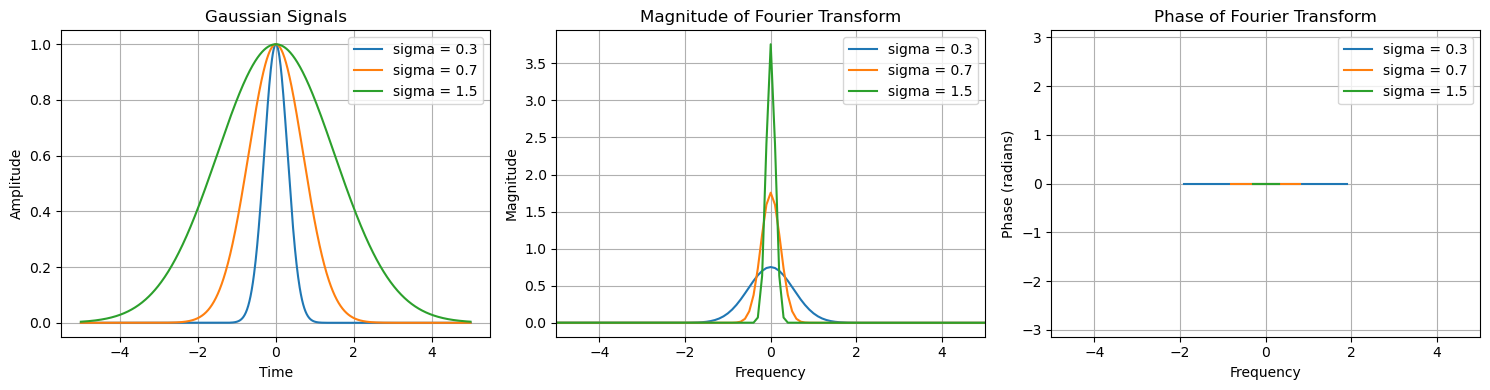

In [65]:
# Setup
N = 1000
t = np.linspace(-5, 5, N, endpoint=False)
dt = t[1] - t[0]

sigmas = [0.3, 0.7, 1.5]

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

for sigma in sigmas:
    # Gaussian signal
    signal = np.exp(-t**2 / (2*sigma**2))

    # FFT
    fft = np.fft.fftshift(np.fft.fft(np.fft.ifftshift(signal)))
    freq = np.fft.fftshift(np.fft.fftfreq(N, dt))

    # Phase with relative magnitude threshold
    phase = np.angle(fft)
    phase[np.abs(fft) < 1e-3 * np.abs(fft).max()] = np.nan

    # Plot
    ax[0].plot(t, signal, label=f'sigma = {sigma}')
    ax[1].plot(freq, np.abs(fft)*dt, label=f'sigma = {sigma}')
    ax[2].plot(freq, phase, label=f'sigma = {sigma}')

# Signal
ax[0].set_title('Gaussian Signals')
ax[0].set_xlabel('Time')
ax[0].set_ylabel('Amplitude')

# Magnitude
ax[1].set_title('Magnitude of Fourier Transform')
ax[1].set_xlabel('Frequency')
ax[1].set_ylabel('Magnitude')
ax[1].set_xlim(-5, 5)

# Phase
ax[2].set_title('Phase of Fourier Transform')
ax[2].set_xlabel('Frequency')
ax[2].set_ylabel('Phase (radians)')
ax[2].set_xlim(-5, 5)
ax[2].set_ylim(-np.pi, np.pi)

# Formatting
for a in ax:
    a.legend()
    a.grid()

plt.tight_layout()
fig.savefig('exe10_problem1.png', dpi=300)
plt.show()

### Problem 2: Signal Processing in 1D (Fill in the blanks/Code to get to the desired result)

Steps performed: 

1) Create a composite signal from multiple sinusoids with three frequencies, get fft of clean signal
2) Add noise (gaussian noise)
3) Add a window (Hann)
4) Get fft of the noisy signal
5) filter frequencies below a threshold
6) get the inverse fft
7) compare the result

Discussion: Try running the procedure with a lower number of N (N<25000). What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why? (Answer in ~3 sentences)


(0.0, 0.3)

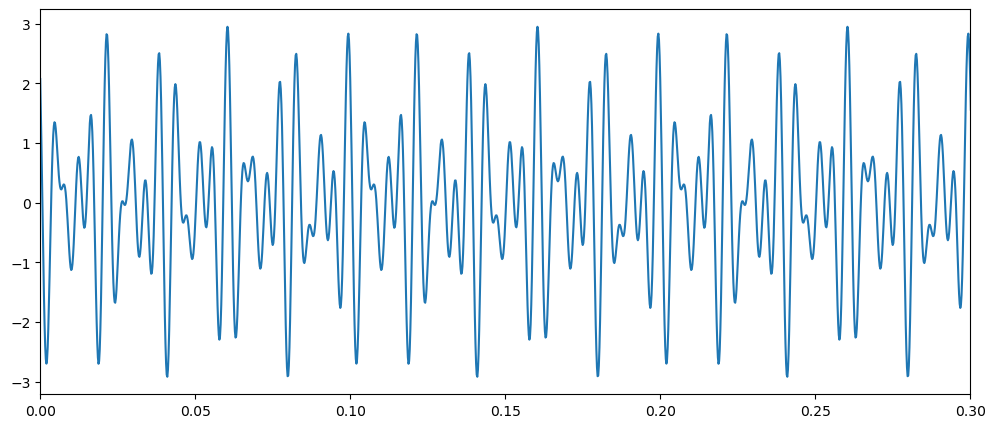

In [43]:
# STEP 1.1

#Make a wave (cosine or sine) - you can do combo of waves
N = 25000
dt = 0.0002 #if spacing is 0.0002, then frequency is 5000 Hz 
t_ = np.arange(N)*dt
freqs = [130, 230, 180]
phase = [np.pi/3, np.pi/4, np.pi/6]

signal_original = np.sum([np.cos(2*np.pi*f*t_ + p) for f, p in zip(freqs, phase)], axis=0)

fft_original = np.fft.fft(signal_original)
freq_original = np.fft.fftfreq(N, dt)

fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, signal_original)
ax.set_xlim(0,0.3)

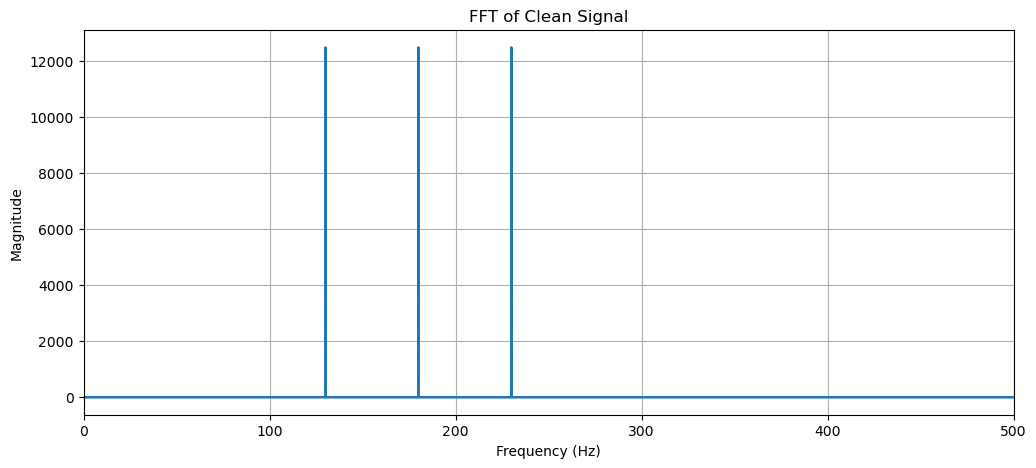

In [44]:
# STEP 1.2

#FILL: Plot the fourier transform of the clean, original signal

# Plot FFT of clean signal
fig, ax = plt.subplots(figsize=(12,5))
ax.plot(freq_original, np.abs(fft_original))
ax.set_xlim(0, 500)
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('Magnitude')
ax.set_title('FFT of Clean Signal')
ax.grid()
plt.show()

(0.0, 0.3)

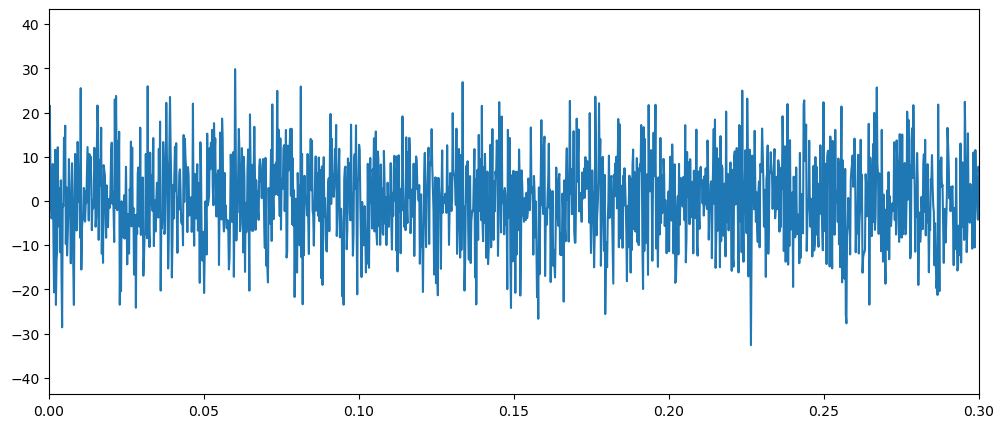

In [45]:
# STEP 2

rng = np.random.default_rng()

#Define parameters of Gaussian noise)
mean = 0
std = 2

noise = rng.normal(loc = mean, scale = std, size = len(t_)) #Add noise to every data point
#Noisy data here
noisy_data = signal_original + noise*5

fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, noisy_data)
ax.set_xlim(0,0.3)

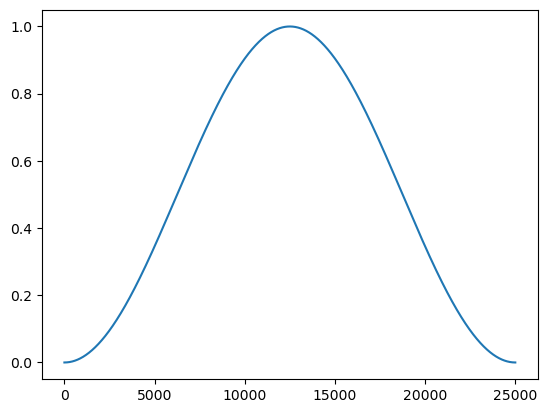

In [10]:
# STEP 3.1

window = np.hanning(len(noisy_data)) #Create a window the size of the data length
plt.plot(window)

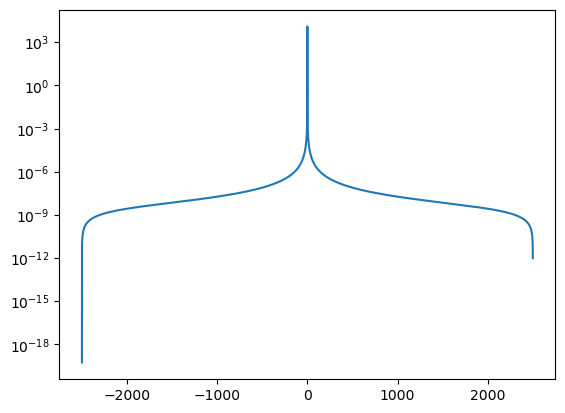

In [46]:
# STEP 3.2

#fourier of hanning window
windowSigPeaks = np.abs(np.fft.fftshift(np.fft.fft(window)))
windowSigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))

plt.plot(windowSigFreqs, windowSigPeaks)
plt.yscale('log')

In [19]:
# STEP 4.1

noisyFourier = np.fft.fft(noisy_data*window)
noisySigPeaks = np.abs(np.fft.fftshift(np.fft.fft(noisy_data*window)))

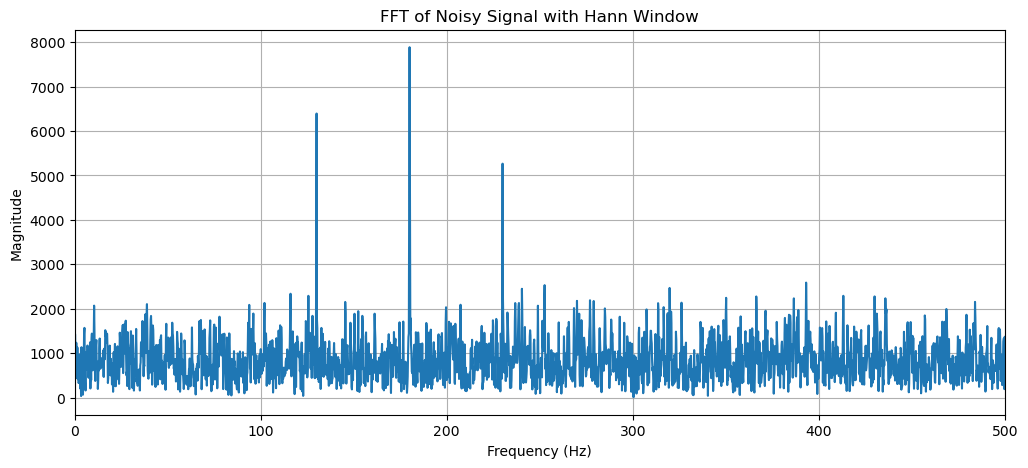

In [34]:
# STEP 4.2

# Fill: Plot the magnitude of fourier transform of the noisy data multiplied by the hanning window

# Plot FFT of noisy data multiplied by Hann window
noisySigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))

fig, ax = plt.subplots(figsize=(12,5))
ax.plot(noisySigFreqs, noisySigPeaks)
ax.set_xlim(0, 500)
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('Magnitude')
ax.set_title('FFT of Noisy Signal with Hann Window')
ax.grid()
plt.show()

In [49]:
# STEP 5

# Fill: Find a suitable threshold value to filter the noise in fourier space

# Set threshold for filtering
threshold = 4500

# Remove frequencies below threshold
filteredFourier = noisyFourier.copy()
filteredFourier[np.abs(noisyFourier) < threshold] = 0

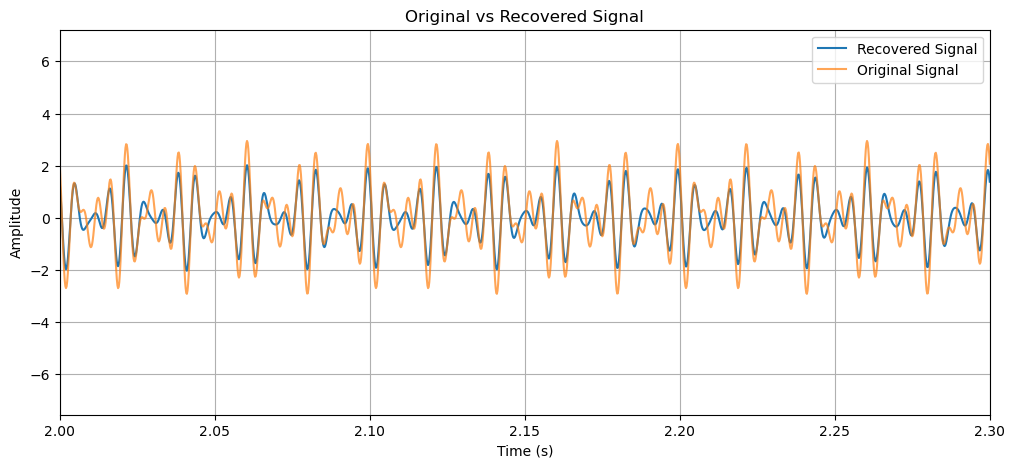

In [66]:
# STEP 6

# Convert filtered FFT back to time domain
signal_cleaned = np.fft.ifft(filteredFourier).real

# Correct for the Hann window
valid = window > 0.2
recoveredSignal = signal_cleaned[valid] / window[valid]

# STEP 7

# Plot recovered signal against original signal
fig, ax = plt.subplots(figsize=(12,5))
ax.plot(t_[valid], recoveredSignal, label='Recovered Signal')
ax.plot(t_, signal_original, label='Original Signal', alpha=0.7)
ax.set_xlim(2, 2.3)
ax.set_xlabel('Time (s)')
ax.set_ylabel('Amplitude')
ax.set_title('Original vs Recovered Signal')
ax.legend()
ax.grid()
fig.savefig('exe10_problem2.png', dpi=300)
plt.show()

### Problem 3: Aliasing
1) Using different sampling frequencies (uniform sampling), generate a sinusoidal signal. Note the sampling frequencies, and the signal frequency. Use a sampling frequency above the Nyquist frequency, and another one below it.
2) Get their fourier transforms. Are they the same?
3) Plot: Show the fourier transform of an aliased signal, how it looks like in the time-domain, and how the actual signal looks like in the time domain if it's not aliased.
   
Discussion: Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave

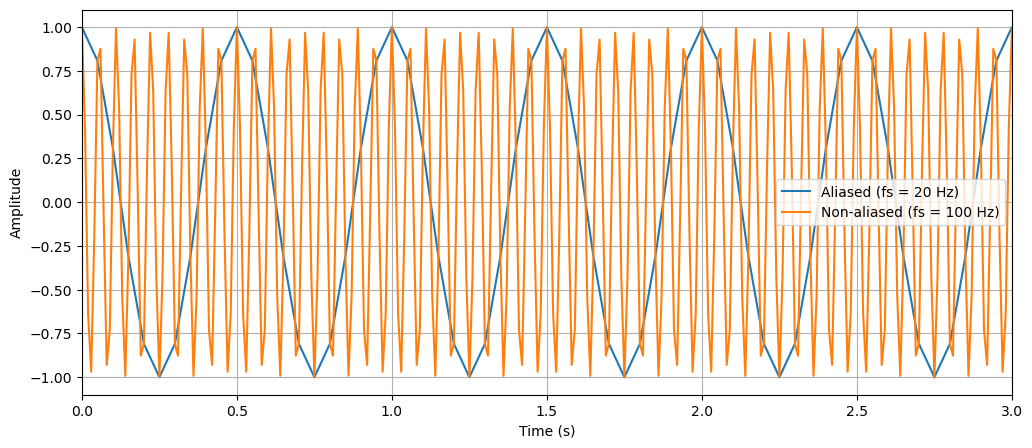

In [61]:
# STEP 1

N_sample = 200
N_unaliased = 1000

t = 10
dt = t/N_sample
dt_un = t/N_unaliased

t_sample = np.arange(N_sample)*dt
t_unaliased = np.arange(N_unaliased)*dt_un

cont_signal = lambda t, freq: np.cos(2*np.pi*freq*t)

# Signal frequency
freq = 18

# Uniform sampling
discrete_signal = cont_signal(t_sample, freq)
dis_unaliased = cont_signal(t_unaliased, freq)

# Plot signals
fig, ax = plt.subplots(figsize=(12,5))

ax.plot(t_sample, discrete_signal, label="Aliased (fs = 20 Hz)")
ax.plot(t_unaliased, dis_unaliased, label="Non-aliased (fs = 100 Hz)")

ax.set_xlim(0, 3)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude")
ax.legend()
ax.grid()

plt.show()

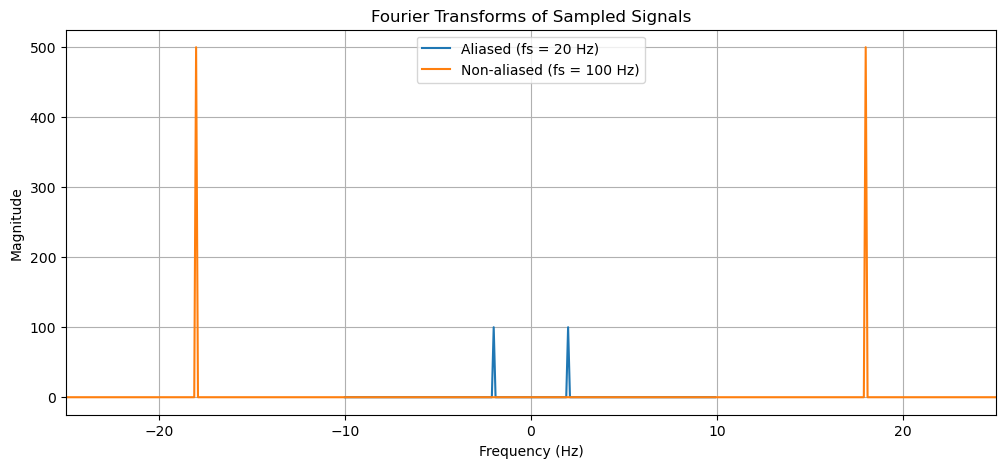

In [62]:
# STEP 2

# Fourier transforms
fft = np.fft.fft(discrete_signal)
fft_un = np.fft.fft(dis_unaliased)

# Frequency axes
freq_sample = np.fft.fftfreq(N_sample, dt)
freq_unaliased = np.fft.fftfreq(N_unaliased, dt_un)

# Plot Fourier transforms
plt.figure(figsize=(12, 5))

plt.plot(np.fft.fftshift(freq_sample),
         np.fft.fftshift(abs(fft)),
         label="Aliased (fs = 20 Hz)")

plt.plot(np.fft.fftshift(freq_unaliased),
         np.fft.fftshift(abs(fft_un)),
         label="Non-aliased (fs = 100 Hz)")

plt.xlim(-25, 25)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Fourier Transforms of Sampled Signals")
plt.legend()
plt.grid()
plt.show()

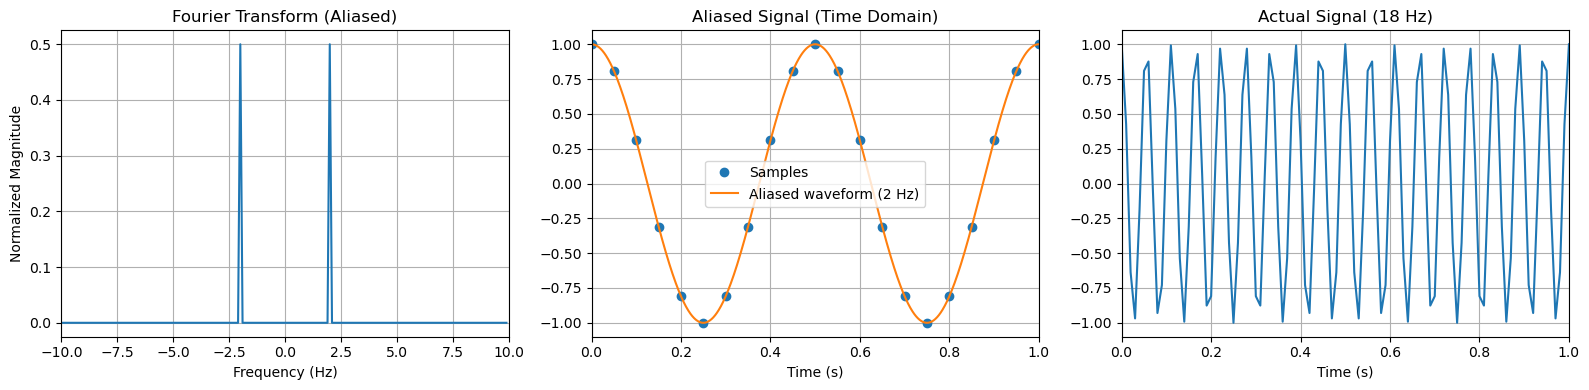

In [77]:
# Plot
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

# Fourier transform
ax[0].plot(np.fft.fftshift(freq_sample), np.fft.fftshift(np.abs(fft)) / N_sample)

ax[0].set_title("Fourier Transform (Aliased)")
ax[0].set_xlabel("Frequency (Hz)")
ax[0].set_ylabel("Normalized Magnitude")
ax[0].set_xlim(-10, 10)
ax[0].grid()

# Aliased signal in time domain
sample_indices = t_sample <= 1

ax[1].plot(t_sample[sample_indices],discrete_signal[sample_indices], 'o', label="Samples")

ax[1].plot(t_cont, aliased_signal, label="Aliased waveform (2 Hz)")

ax[1].set_title("Aliased Signal (Time Domain)")
ax[1].set_xlabel("Time (s)")
ax[1].set_xlim(0, 1)
ax[1].legend()
ax[1].grid()

# Actual signal in time domain
ax[2].plot(t_unaliased[t_unaliased <= 1], dis_unaliased[t_unaliased <= 1])

ax[2].set_title("Actual Signal (18 Hz)")
ax[2].set_xlabel("Time (s)")
ax[2].set_xlim(0, 1)
ax[2].grid()

plt.tight_layout()
fig.savefig('exe10_problem3.png', dpi=300)
plt.show()

#### Problem code summary

In Problem 1, we examined how varying the Gaussian's width affects its Fourier magnitude and phase spectra. In Problem 2, we added Gaussian noise to a composite signal, applied a Hann window, filtered its Fourier transform, and reconstructed the signal using the inverse FFT. In Problem 3, we compared sampling an 18 Hz sinusoid at 20 Hz and 100 Hz, demonstrating how undersampling causes aliasing and makes the signal appear to have a frequency of 2 Hz.

---
## Section 3: Notes

In [15]:
import numpy as np
import matplotlib.pyplot as plt

### Fourier transform (from $t$-space to $\omega$-space)
$$ Y(\omega) = \int_{-\infty}^{+\infty} dt \frac{e^{-i\omega t}}{\sqrt{2\pi}}y(t)$$

### Inverse Fourier transform (from $\omega$-space to $t$-space)
$$ y(t) = \int_{-\infty}^{+\infty} d\omega Y(\omega) \frac{e^{i\omega t}}{\sqrt{2\pi}}$$

Something to think about: while we essentially do numerical integration, we do not impose h. Instead, we utilize the spacing of the dataset.

### Discrete FT/IFT

$$ Y_n = \frac{1}{\sqrt{2\pi}} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{y_k\}  +\sin(nk\theta)\Im\{y_k\} +i(\cos(nk\theta)\Im\{y_k\} −\sin(nk\theta)\Re\{y_k\})]\right]$$

$$ y_k = \frac{\sqrt{2\pi}}{N} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{Y_n\}  -\sin(nk\theta)\Im\{Y_n\} +i(\cos(nk\theta)\Im\{Y_n\} +\sin(nk\theta)\Re\{Y_n\})]\right]$$

Why bother it doing this way? 

It cleanly splits the real and imaginary part for both inputs and outputs, so that you can use a pair of floats rather than an aggregate complex data type (complex128 is just a pair of float64 anyway).

Using $Z=e^{−i\theta}, \rightarrow Z^{\pm nk} = e^{\mp ink\theta} = \cos(nk\theta)\mp i\sin(nk\theta)$.

(0.0, 4.0)

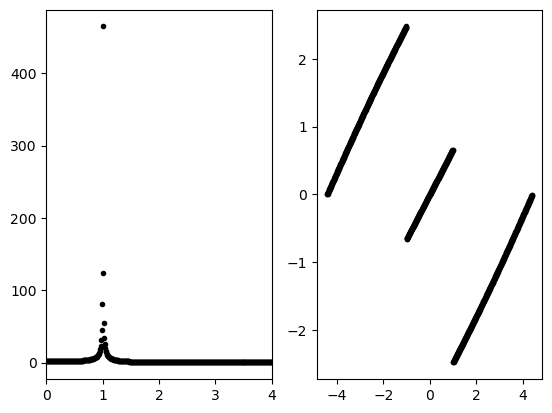

In [16]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
x = np.linspace(0, 18*2*np.pi, N)
deltaT = x[1] - x[0]

f = 1
y = np.cos(2*np.pi*f*x)

freqs = np.fft.fftfreq(N, deltaT)
Yk = np.fft.fft(y)

# # Q: Why do fftshift?
# Yk = np.fft.fftshift(Yk)

Yk_mag = np.abs(Yk)
Yk_phase = np.angle(Yk)
# Q: Why unwrap?
Yk_phase = np.unwrap(Yk_phase)

fig, ax = plt.subplots(1,2)

ax[0].plot(freqs, Yk_mag, "k.")
ax[1].plot(freqs, Yk_phase, "k.")
ax[0].set_xlim(0, 4)

### Waveforms of interest
- Sinusoid (single frequency, varying phase shift)
- Sum of sinusoids with different frequencies and phases
- Product of sinusoids with different frequencies and phases
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function
- Finite-time sinusoid
- Gaussian wave packet

In [17]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
x = np.sin(2*np.pi*2*t)

Text(0, 0.5, 'x')

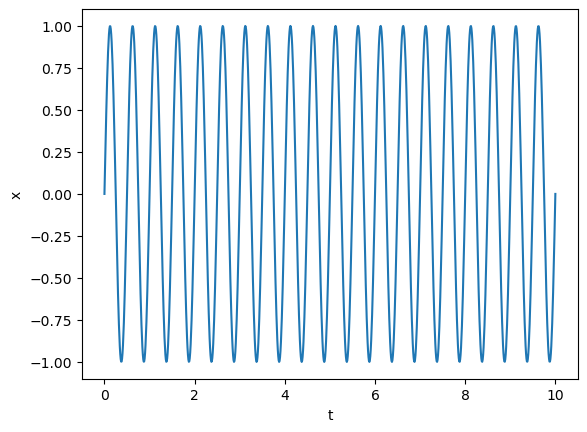

In [18]:
plt.plot(t,x)
plt.xlabel("t")
plt.ylabel("x")

In [19]:
x_ft = np.fft.fft(x)
np.fft.fftfreq?

Signature: np.fft.fftfreq(n, d=1.0)
Docstring:
Return the Discrete Fourier Transform sample frequencies.

The returned float array `f` contains the frequency bin centers in cycles
per unit of the sample spacing (with zero at the start).  For instance, if
the sample spacing is in seconds, then the frequency unit is cycles/second.

Given a window length `n` and a sample spacing `d`::

  f = [0, 1, ...,   n/2-1,     -n/2, ..., -1] / (d*n)   if n is even
  f = [0, 1, ..., (n-1)/2, -(n-1)/2, ..., -1] / (d*n)   if n is odd

Parameters
----------
n : int
    Window length.
d : scalar, optional
    Sample spacing (inverse of the sampling rate). Defaults to 1.

Returns
-------
f : ndarray
    Array of length `n` containing the sample frequencies.

Examples
--------
>>> signal = np.array([-2, 8, 6, 4, 1, 0, 3, 5], dtype=float)
>>> fourier = np.fft.fft(signal)
>>> n = signal.size
>>> timestep = 0.1
>>> freq = np.fft.fftfreq(n, d=timestep)
>>> freq
array([ 0.  ,  1.25,  2.5 , ..., -3.75, -2.5 , -1

### Plotting

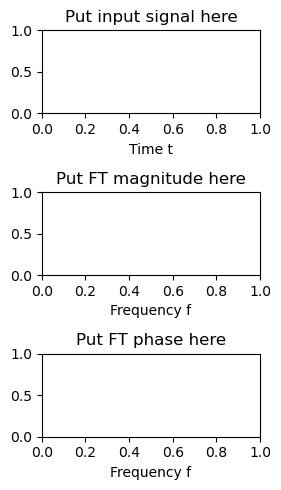

In [20]:
fig, ax = plt.subplots(3, 1, figsize=(3, 5))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

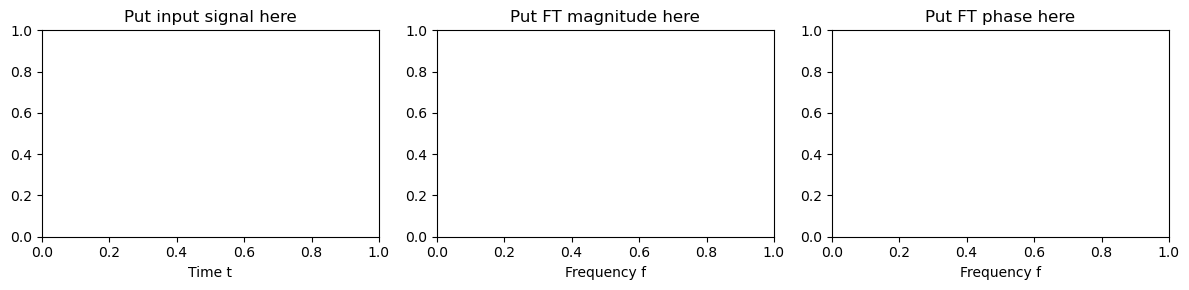

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

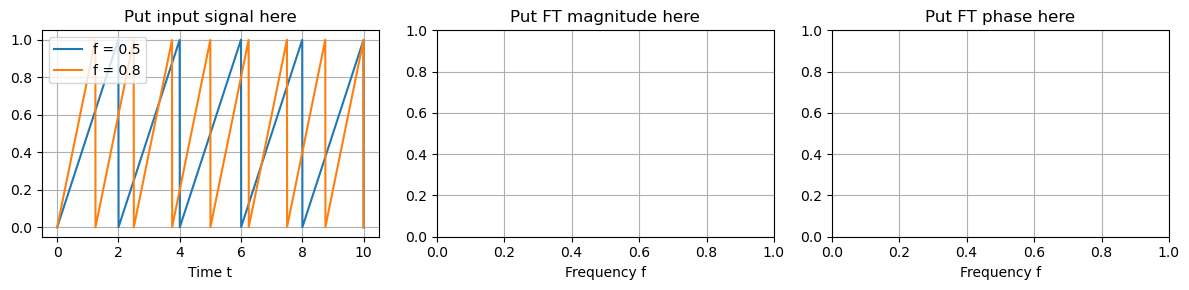

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
ax_t, ax_f, ax_p = axs

t = np.linspace(0, 10, 2048)
f = 0.5 # Frequency
T = 1/(f) # Period
f2 = 0.8 # Frequency
T2 = 1/(f2) # Period


ax_t.set_title("Put input signal here")
ax_t.set_xlabel("Time t")
ax_t.plot(t, (t%T)/T, label="f = 0.5")
ax_t.plot(t, (t%T2)/T2, label="f = 0.8")
ax_t.legend()
#....
ax_f.set_title("Put FT magnitude here")
ax_f.set_xlabel("Frequency f")
#....
ax_p.set_title("Put FT phase here")
ax_p.set_xlabel("Frequency f")
#...


for ax in axs:
    ax.grid(True)
fig.tight_layout()

## 1-D convolution

In [23]:
a = [1,1,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,1,0,1,1,0,0,0,0]
v = [1,1,1]



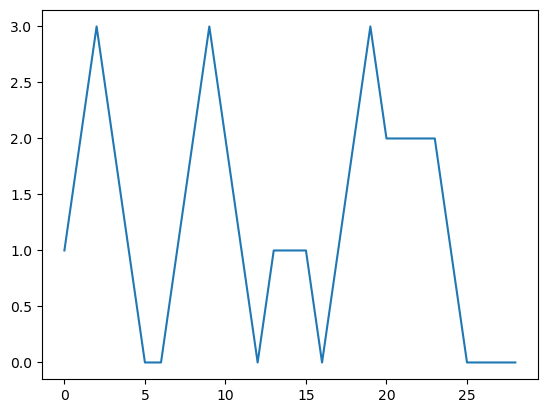

In [24]:
plt.plot(np.arange(len(np.convolve(a,v, mode='full'))), np.convolve(a,v, mode='full'))

### Convolution attempt (bringing circuits analogy) 

In [18]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
N = 500
t = np.linspace(0, 1, N, endpoint=False)
t_input = np.linspace(0, 5, N*5, endpoint=False)
signal_freq = 5
# dt = t[1] - t[0]
# nonsinu_signal = signal.square(2 * np.pi * signal_freq * t)

In [19]:
tau = 0.1
h_t = np.exp(-t/tau)
input_signal = signal.square(2 * np.pi * signal_freq * t_input) #cont_signal(t, freq)

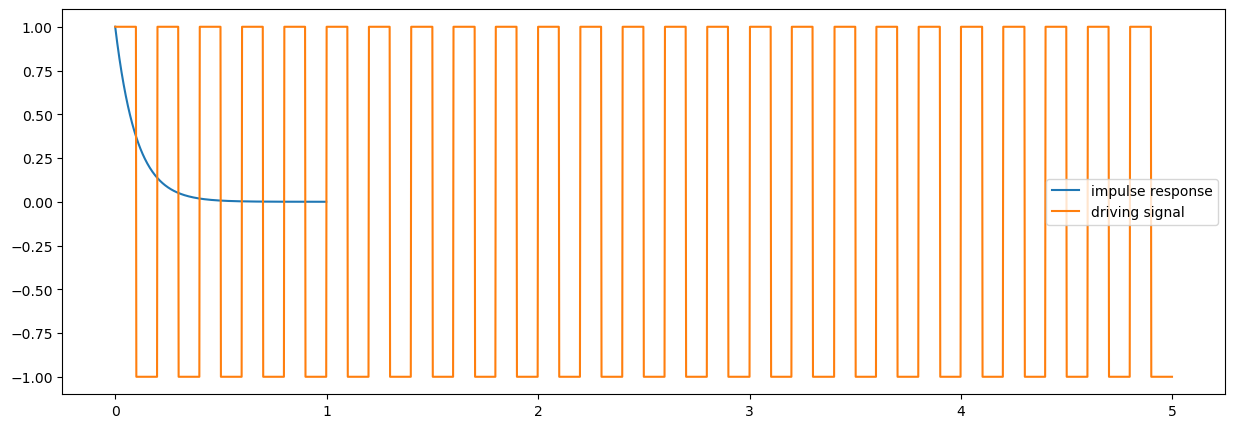

In [20]:
fig, ax = plt.subplots(figsize = (15,5))
ax.plot(t, h_t, label = "impulse response")
ax.plot(t_input, input_signal, label= "driving signal")
ax.legend()

In [21]:
response = np.convolve(input_signal, h_t, mode = "same")

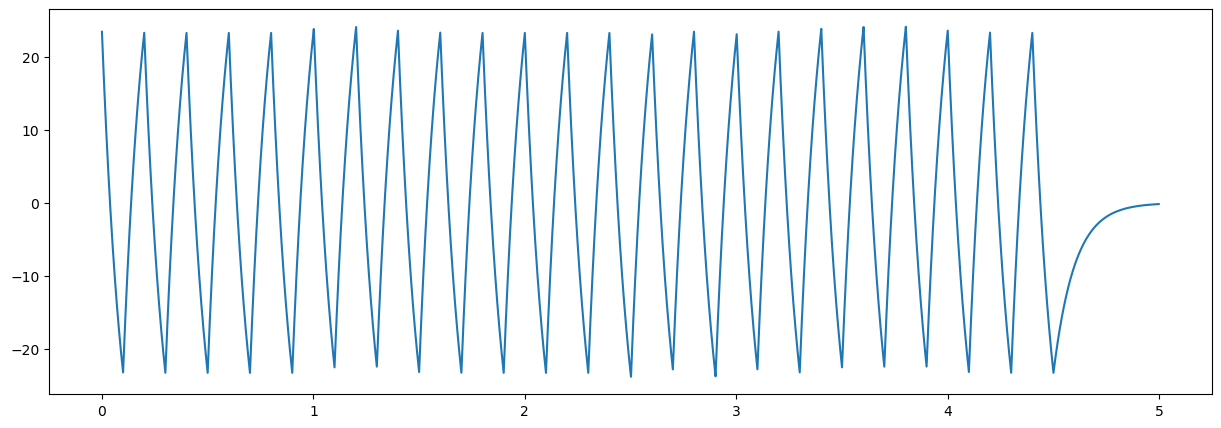

In [22]:
fig, ax = plt.subplots(figsize = (15,5))
#ax.plot(t, input_signal)
ax.plot(t_input, response)

In [23]:
fourier_length = len(h_t) + len(input_signal) - 1

In [24]:
fourier_input = np.fft.fft(input_signal, n = fourier_length)
fourier_h = np.fft.fft(h_t, n = fourier_length)

In [25]:
fourier_response = fourier_h*fourier_input 

In [26]:
response = np.real(np.fft.ifft(fourier_response))

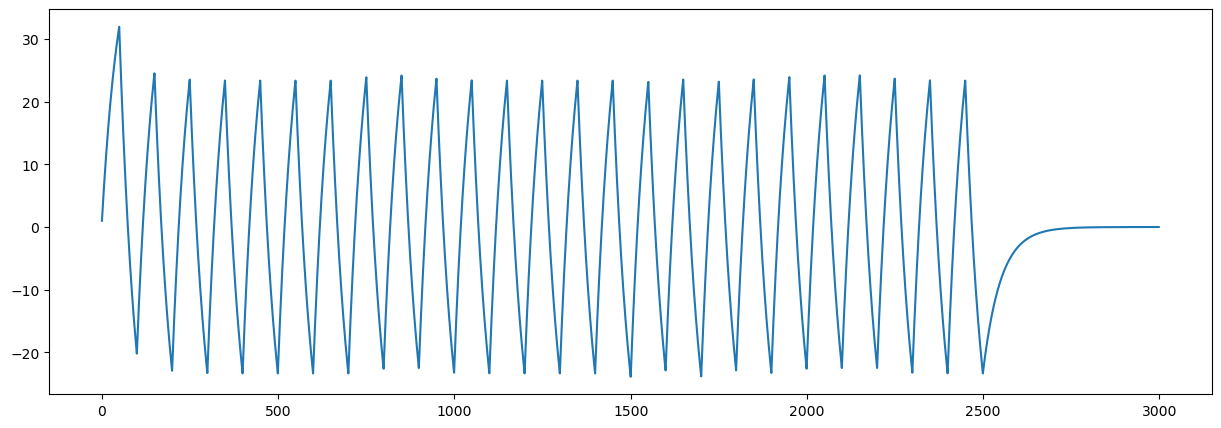

In [27]:
fig, ax = plt.subplots(figsize = (15,5))

ax.plot(response)